# 05 · Regression detection

1. **Device level:** which updated devices changed abnormally compared with the control distribution?
2. **Time level:** CUSUM on the treatment-minus-control gap, to find *when* behaviour changed.
3. **Detector validation:** the rolling z-score anomaly detector, scored against NAB's real labelled anomaly windows.
4. **Decision:** CONTINUE / INVESTIGATE / ROLLBACK, per segment.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
P = ROOT / "data" / "processed"

In [2]:
from src.performance_metrics import device_period_kpis
from src.regression_detection import device_regression_scores, fleet_change_point, evaluate_detector_on_nab, rollout_decision
from src.preprocessing import load_all_nab
tel = pd.read_parquet(P / "telemetry.parquet"); kpis = device_period_kpis(tel)
scores = device_regression_scores(kpis)
print(f"{scores.regression_flag.sum()} of {len(scores)} updated devices flagged")
pd.crosstab(scores.hw_revision, scores.regression_flag, margins=True)

27 of 92 updated devices flagged


regression_flag,False,True,All
hw_revision,,,
A,65,1,66
B,0,26,26
All,65,27,92


In [3]:
scores.head(15)

period,device_id,hw_revision,region,z_fw_errors_per_100,z_uptime_pct,z_reboots_per_100,z_sensor_jitter,z_mean_rms,z_alarm_rate_pct,z_p50_response_ms,z_p95_response_ms,worst_metric,worst_z,n_metrics_flagged,regression_flag
0,DEV-0036,B,APAC,0.0000,2.2559,2.0702,6.7645,57.9265,5.4969,15.1326,12.3220,mean_rms,57.9265,5,True
1,DEV-0126,A,APAC,0.0000,1.9146,0.0000,3.0472,50.7902,6.3835,-8.2653,-6.5560,mean_rms,50.7902,3,False
2,DEV-0035,A,NA-East,-0.6745,-0.0000,0.0000,-2.9687,30.7368,1.5959,-7.7967,-6.6531,mean_rms,30.7368,1,False
3,DEV-0009,B,NA-East,1.6862,-0.1369,0.0000,-1.1288,24.1638,0.0000,16.7477,13.5054,mean_rms,24.1638,3,True
4,DEV-0100,A,APAC,-1.0117,0.1538,2.0702,-1.7613,23.1840,0.0000,-10.7173,-7.6049,mean_rms,23.1840,1,False
5,DEV-0044,A,APAC,0.0000,-0.0000,0.0000,-3.2456,22.3555,-0.1773,-9.3803,-7.9721,mean_rms,22.3555,1,False
6,DEV-0005,B,NA-East,0.3372,0.0983,2.0702,-2.7777,10.3050,0.0000,22.2011,15.7267,p50_response_ms,22.2011,3,True
7,DEV-0091,B,APAC,2.0235,0.3480,4.1404,-3.9863,5.4270,0.0000,22.1929,16.4694,p50_response_ms,22.1929,4,True
8,DEV-0017,A,NA-East,-0.3372,-0.0000,0.0000,-1.2406,21.8516,0.0000,-6.9285,-7.0710,mean_rms,21.8516,1,False
9,DEV-0085,B,APAC,-1.3490,-0.0000,0.0000,-2.6018,5.0795,0.0000,21.5441,15.5731,p50_response_ms,21.5441,3,True


[Text(0.5, 0, 'P95 response z (worse ->)'),
 Text(0, 0.5, 'FW error z (worse ->)'),
 Text(0.5, 1.0, 'Device regression map')]

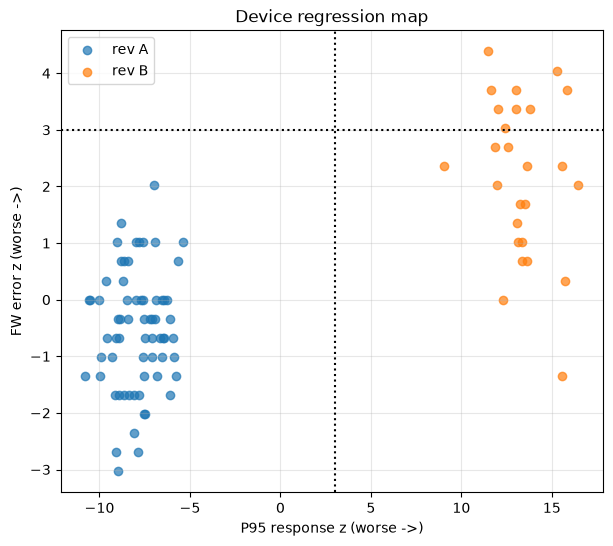

In [4]:
fig, ax = plt.subplots(figsize=(7, 6))
for rev, g in scores.groupby("hw_revision"):
    ax.scatter(g.z_p95_response_ms, g.z_fw_errors_per_100, label=f"rev {rev}", alpha=0.7)
ax.axhline(3, ls=":", c="k"); ax.axvline(3, ls=":", c="k"); ax.legend()
ax.set(xlabel="P95 response z (worse ->)", ylabel="FW error z (worse ->)", title="Device regression map")

### Change-point detection

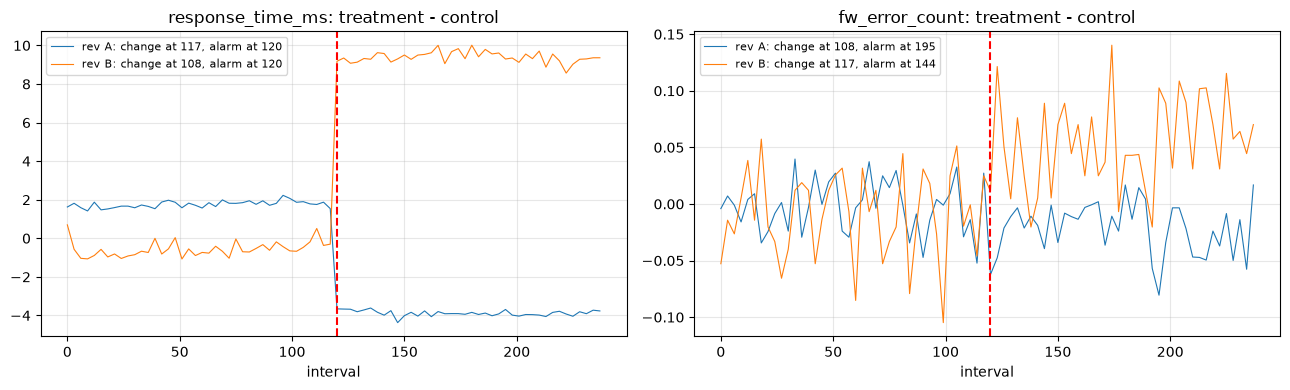

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, m in zip(axes, ["response_time_ms", "fw_error_count"]):
    for rev in ["A", "B"]:
        cp = fleet_change_point(tel, m, rev)
        x = np.arange(len(cp["gap"])) * cp["bucket"]
        ax.plot(x, cp["gap"], lw=0.8, label=f"rev {rev}: change at {cp['change_point_interval']}, alarm at {cp['first_alarm_interval']}")
    ax.axvline(120, color="red", ls="--"); ax.set_title(f"{m}: treatment - control"); ax.legend(fontsize=8); ax.set_xlabel("interval")
plt.tight_layout()

### Validating the anomaly detector on NAB
Precision is low on some series. That is useful on its own: it shows a simple z-score detector should not be the only
basis for a rollback, which is why the decision rests on the controlled DiD comparison.

In [6]:
evaluate_detector_on_nab(load_all_nab())

,series,anomaly_windows,windows_detected,false_alarm_events,recall,precision
0,machine_temperature_system_failure,4,2,20,0.5,0.0909
1,ec2_request_latency_system_failure,3,3,0,1.0,1.0000
2,ambient_temperature_system_failure,2,1,2,0.5,0.3333
3,cpu_utilization_asg_misconfiguration,1,0,46,0.0,0.0000
4,ec2_cpu_utilization_825cc2,1,1,4,1.0,0.2000


### Rollout decision
Rules (`src/regression_detection.py`):
* **ROLLBACK**: a guardrail metric (firmware errors, uptime, reboots, P95 latency) regresses significantly (FDR-adjusted p < 0.05) by at least 20%, or uptime regresses significantly.
* **INVESTIGATE**: any other significant regression, or more than 10% of updated devices individually flagged.
* **CONTINUE**: otherwise.

In [7]:
d = rollout_decision(kpis)
print(d["headline"], "\n")
for seg, v in d["decisions"].items():
    print(f"{seg:15s} {v['decision']}")
    for r in v["reasons"]: print("   -", r)

Segment-specific: hw_revision=B -> ROLLBACK; CONTINUE for hw_revision=A. 

fleet           INVESTIGATE
   - Mean vibration RMS (g) regressed +4.2% (adj. p=0.00221)
   - 29% of updated devices individually flagged
hw_revision=A   CONTINUE
   - Firmware errors / 100 intervals improved -45.5%
   - Sensor jitter (rel. step-to-step change) improved -63.6%
   - Median response time (ms) improved -12.2%
   - P95 response time (ms) improved -12.6%
hw_revision=B   ROLLBACK
   - Firmware errors / 100 intervals: +161.9% vs control (adj. p=2.22e-07)
   - Reboots / 100 intervals: +200.0% vs control (adj. p=0.00453)
   - P95 response time (ms): +21.7% vs control (adj. p=2.29e-30)


### Validation against ground truth
The injected multipliers (notebook 02) and the estimated ones should agree within their CIs.

In [8]:
truth = json.loads((ROOT / "data/firmware_metadata/firmware_effects_ground_truth.json").read_text())["effects_v2_vs_v1"]
seg = d["by_segment"].set_index(["segment", "metric"])
rows = []
for rev in "AB":
    for metric, key in [("fw_errors_per_100", "fw_error_rate"), ("p50_response_ms", "response_time"), ("mean_rms", "rms_gain")]:
        r = seg.loc[(f"hw_revision={rev}", metric)]
        rows.append({"rev": rev, "metric": metric, "injected": truth[key][rev], "estimated": 1 + r.did / r.treatment_pre,
                     "ci": f"[{1 + r.ci_low / r.treatment_pre:.2f}, {1 + r.ci_high / r.treatment_pre:.2f}]"})
pd.DataFrame(rows)

,rev,metric,injected,estimated,ci
0,A,fw_errors_per_100,0.75,0.5449,"[0.28, 0.80]"
1,A,p50_response_ms,0.88,0.8783,"[0.87, 0.88]"
2,A,mean_rms,1.00,1.0280,"[1.00, 1.05]"
3,B,fw_errors_per_100,2.20,2.6188,"[2.16, 3.09]"
4,B,p50_response_ms,1.22,1.2221,"[1.21, 1.23]"
5,B,mean_rms,1.06,1.0793,"[1.04, 1.13]"
